In [1]:
# for latex rendering


import matplotlib as mpl
import matplotlib.pyplot as plt
plt.rcParams['savefig.dpi'] = 75
mpl.rcParams.update({'font.size': 22, 'font.family': 'serif'})
plt.rcParams['figure.autolayout'] = False
plt.rcParams['figure.figsize'] = 10, 6 #6.4, 4.8
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['font.size'] = 16
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 15
mpl.rc('axes',edgecolor='k')
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams["axes.axisbelow"] = False
plt.rcParams["xtick.major.size"] = 6
plt.rcParams["xtick.minor.size"] = 3
plt.rcParams["ytick.major.size"] = 6
plt.rcParams["ytick.minor.size"] = 3
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['text.usetex'] = True 
colors = plt.get_cmap('tab10')


In [2]:
# S2 interpolation, Gaussian-0.10 smoothing, and the accepted smooth correction.
from pathlib import Path
import numpy as np
from scipy.interpolate import BSpline, CubicSpline
from scipy.ndimage import gaussian_filter1d
from scipy.integrate import cumulative_trapezoid

GAUSSIAN_SIGMA_LNT = 0.10
N_T = 3000
GAUSSIAN_N_T = 5000  # Same smoothing grid as the accepted cubic+gaussian_010 fit.
APPLY_W_CORRECTION = True

PROJECT_CANDIDATES = [
    Path.cwd(), Path.cwd() / 'sigw' / 'SIGW_EOS' / 'SIGW_EOS',
    Path.cwd().parent,
]
PROJECT_DIR = next((p.resolve() for p in PROJECT_CANDIDATES
                    if (p / 'SMbackground.ipynb').exists()
                    and (p / 'transferfunction').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Set PROJECT_DIR to the SMbackground notebook directory.')

S2_LOG10_T = np.array([
    0.00, 0.50, 1.00, 1.25, 1.60, 2.00, 2.15, 2.20,
    2.40, 2.50, 3.00, 4.00, 4.30, 4.60, 5.00, 5.45,
])
S2_G_RHO = np.array([
    10.71, 10.74, 10.76, 11.09, 13.68, 17.61, 24.07, 29.84,
    47.83, 53.04, 73.48, 83.10, 85.56, 91.97, 102.17, 104.98,
])
S2_G_RHO_OVER_G_S = np.array([
    1.00228, 1.00029, 1.00048, 1.00505, 1.02159, 1.02324,
    1.05423, 1.07578, 1.06118, 1.04690, 1.01778, 1.00123,
    1.00389, 1.00887, 1.00750, 1.00023,
])

S2_T = 10.0**S2_LOG10_T
LOG_T = np.linspace(np.log(S2_T[0]), np.log(S2_T[-1]), N_T)
T = np.exp(LOG_T)

# Interpolate the positive S2 quantities in log space.
g_rho_spline = CubicSpline(S2_LOG10_T, np.log(S2_G_RHO))
ratio_spline = CubicSpline(S2_LOG10_T, np.log(S2_G_RHO_OVER_G_S))
g_rho_s2 = np.exp(g_rho_spline(LOG_T / np.log(10.0)))
g_rho_over_g_s_s2 = np.exp(ratio_spline(LOG_T / np.log(10.0)))
g_s_s2 = g_rho_s2 / g_rho_over_g_s_s2
w_raw = 4.0 / (3.0 * g_rho_over_g_s_s2) - 1.0

# Reproduce the original smoothing grid before applying the fixed correction.
log_t_smoothing = np.linspace(LOG_T[0], LOG_T[-1], GAUSSIAN_N_T)
w_smoothing_raw = 4.0 / (
    3.0 * np.exp(ratio_spline(log_t_smoothing / np.log(10.0)))
) - 1.0
w_smoothed = gaussian_filter1d(
    w_smoothing_raw,
    GAUSSIAN_SIGMA_LNT / (log_t_smoothing[1] - log_t_smoothing[0]),
    mode='nearest',
)
w_baseline_spline = CubicSpline(log_t_smoothing, w_smoothed)

# Accepted C4 B-spline correction from the S2 fit. The knots are log10(T/MeV);
# the coefficients are dimensionless and multiply a 1e-3 change in w.
CORRECTION_KNOTS_LOG10_T = np.array([
    -0.80000000000000004, -0.55517241379310356, -0.31034482758620696, -0.065517241379310365,
    0.17931034482758612, 0.42413793103448261, 0.66896551724137931, 0.9137931034482758,
    1.1586206896551723, 1.403448275862069, 1.6482758620689653, 1.893103448275862,
    2.1379310344827589, 2.3827586206896552, 2.6275862068965514, 2.8724137931034477,
    3.1172413793103448, 3.3620689655172411, 3.6068965517241383, 3.8517241379310345,
    4.0965517241379308, 4.3413793103448279, 4.5862068965517242, 4.8310344827586205,
    5.0758620689655176, 5.3206896551724139, 5.5655172413793101, 5.8103448275862064,
    6.0551724137931036, 6.2999999999999998,
])
CORRECTION_COEFFICIENTS = np.array([
    0.0025935776943754843, -0.003266942149449044, 0.0046964239976301459, -0.0071667852741869988,
    0.011212545485410471, -0.017790409842819564, 0.028698082487518255, -0.04654903841952826,
    0.080355724452102498, -0.13484564330682089, 0.3353149373110374, 0.30764159129878416,
    -0.086464707346890199, 0.067114183202084565, -0.064055300652566552, 0.059944839266058925,
    -0.090527634981075925, 0.12086760575276141, -0.19869119714284791, 0.29493357514952789,
    -0.38871459124773594, -0.77750730795403167, -0.70187345884186614, 0.3240126697601256,
])
CORRECTION_SCALE = 0.001

# w_new = w_010 + scale * sum(theta_i B_i); derive cs2 from this same w.
def constructed_eos(log_temperature):
    x = np.atleast_1d(np.asarray(log_temperature, dtype=float))
    knots = CORRECTION_KNOTS_LOG10_T * np.log(10.0)
    basis = np.column_stack([
        np.nan_to_num(BSpline.basis_element(knots[j:j + 7], extrapolate=False)(x), nan=0.0)
        for j in range(len(CORRECTION_COEFFICIENTS))
    ])
    dbasis = np.column_stack([
        np.nan_to_num(BSpline.basis_element(knots[j:j + 7], extrapolate=False)(x, 1), nan=0.0)
        for j in range(len(CORRECTION_COEFFICIENTS))
    ])
    coeff = CORRECTION_COEFFICIENTS if APPLY_W_CORRECTION else np.zeros_like(CORRECTION_COEFFICIENTS)
    w_value = w_baseline_spline(x) + CORRECTION_SCALE * basis @ coeff
    dw_value = w_baseline_spline(x, 1) + CORRECTION_SCALE * dbasis @ coeff
    cs2_value = w_value * (1.0 + w_value) / (1.0 + w_value - dw_value)
    return w_value, dw_value, cs2_value

w, dw_dlogT, cs2_ad = constructed_eos(LOG_T)
w_spline = CubicSpline(LOG_T, w)
assert np.all(np.isfinite(cs2_ad)) and np.all(cs2_ad > 0.0)
print('Accepted smooth w correction applied:', APPLY_W_CORRECTION)
print(f'Max |delta w| = {np.max(np.abs(w - w_baseline_spline(LOG_T))):.6g}')


Accepted smooth w correction applied: True
Max |delta w| = 0.000674133


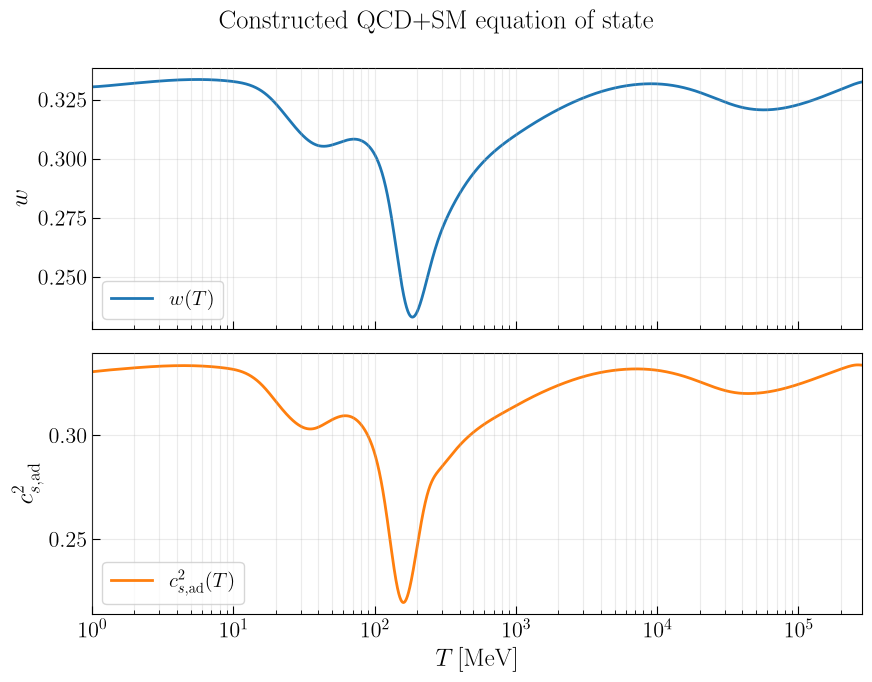

In [3]:
# Plot the constructed QCD+SM w(T) and adiabatic c_s^2(T)
fig, axes = plt.subplots(2, 1, sharex=True, figsize=(9, 7))
axes[0].semilogx(T, w, color='C0', label=r'$w(T)$')
axes[1].semilogx(T, cs2_ad, color='C1', label=r'$c_{s,\mathrm{ad}}^2(T)$')
axes[0].set_ylabel(r'$w$')
axes[1].set_ylabel(r'$c_{s,\mathrm{ad}}^2$')
axes[1].set_xlabel(r'$T\,[\mathrm{MeV}]$')
for ax in axes:
    ax.grid(True, which='both', alpha=0.25)
    ax.legend()
    ax.set_xlim(S2_T[0], S2_T[-1])
fig.suptitle(r'Constructed QCD+SM equation of state')
fig.tight_layout()
plt.show()


In [4]:
# Reconstruct g_rho(T), g_s(T), and g_rho(T)/g_s(T) from the corrected w.
G_RHO_HIGH_T = 104.98

# Equivalent to integrating (1+w)/cs2-4, with -dln(w)/dln(T)
# integrated analytically to avoid unnecessary derivative quadrature error.
log_g_integral = cumulative_trapezoid(1.0 / w - 3.0, LOG_T, initial=0.0)
g_rho_reconstructed = G_RHO_HIGH_T * (w[-1] / w) * np.exp(
    log_g_integral - log_g_integral[-1]
)
g_s_reconstructed = 0.75 * (1.0 + w) * g_rho_reconstructed
g_rho_over_g_s_reconstructed = g_rho_reconstructed / g_s_reconstructed
S2_G_S = S2_G_RHO / S2_G_RHO_OVER_G_S

assert np.isclose(g_rho_reconstructed[-1], G_RHO_HIGH_T)
print(f'Max |delta g_*| = {np.max(np.abs(g_rho_reconstructed-g_rho_s2)):.6f}')
print(f'Max |delta g_*s| = {np.max(np.abs(g_s_reconstructed-g_s_s2)):.6f}')


Max |delta g_*| = 0.720047
Max |delta g_*s| = 0.719990


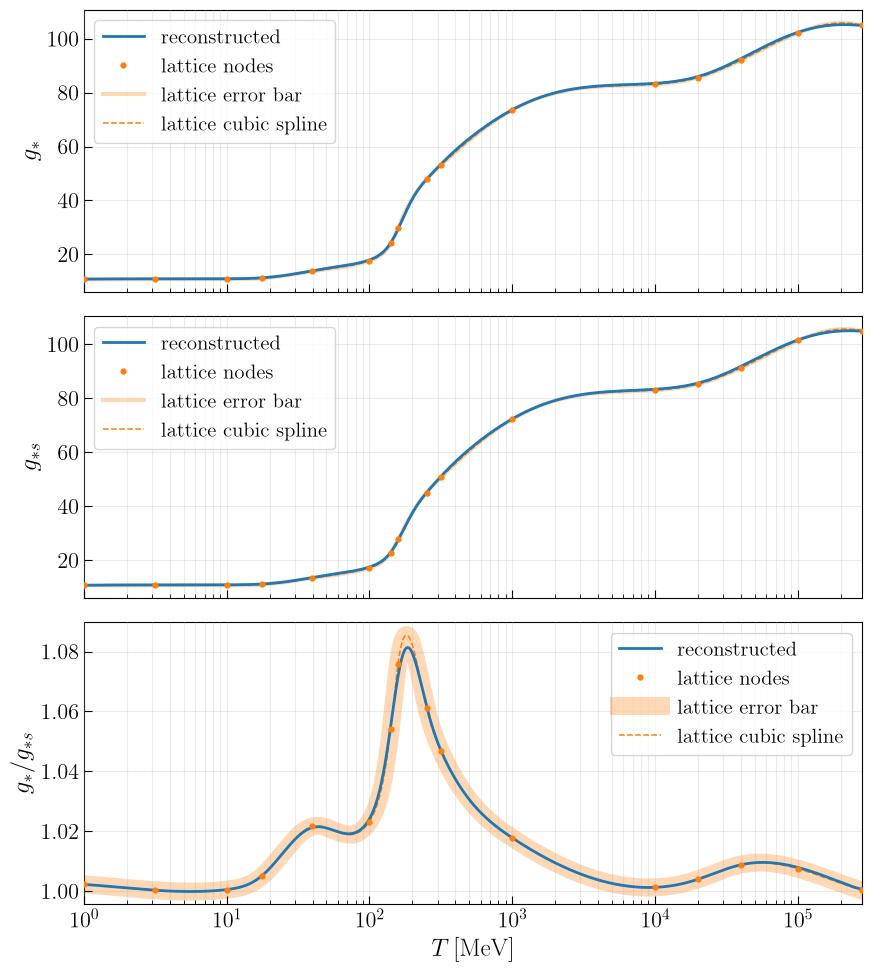

In [5]:
# Compare reconstructed g functions with the S2 interpolation and nodes.
# Fixed data-unit half-widths, converted to constant screen linewidths
# after tight_layout has fixed the axes geometry.
ERROR_HALF_WIDTHS = (0.75, 0.75, 0.003)

s2_reference = (g_rho_s2, g_s_s2, g_rho_over_g_s_s2)
reconstructed = (
    g_rho_reconstructed,
    g_s_reconstructed,
    g_rho_over_g_s_reconstructed,
)
node_values = (S2_G_RHO, S2_G_S, S2_G_RHO_OVER_G_S)
labels = (r'$g_*$', r'$g_{*s}$', r'$g_*/g_{*s}$')

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 10))
error_lines = []
for ax, label, reference, result, nodes in zip(
    axes, labels, s2_reference, reconstructed, node_values
):
    ax.set_xlim(S2_T[0], S2_T[-1])
    ax.semilogx(T, result, color='C0', label='reconstructed', zorder=4)
    ax.semilogx(S2_T, nodes, 'o', color='C1', ms=3.5,
                label='lattice nodes', zorder=5)
    ax.set_ylabel(label)
    ax.grid(True, which='both', alpha=0.25)

    error_lines.append(ax.semilogx(
        T, reference, color='C1', alpha=0.30, lw=1.0,
        label='lattice error bar', zorder=1
    )[0])
    ax.semilogx(T, reference, '--', color='C1', lw=1.1,
                label='lattice cubic spline', zorder=3)
    ax.legend()

axes[-1].set_xlabel(r'$T\,[\mathrm{MeV}]$')
#fig.suptitle(r'Reconstructed effective degrees of freedom')
fig.tight_layout()
fig.canvas.draw()
# Convert each half-width only after the final axes layout is known.
for ax, reference, half_width, line in zip(
    axes, s2_reference, ERROR_HALF_WIDTHS, error_lines
):
    x_ref, y_ref = T[-1], reference[-1]
    y0 = ax.transData.transform((x_ref, y_ref))[1]
    y1 = ax.transData.transform((x_ref, y_ref + half_width))[1]
    line_width_points = 2.0 * abs(y1 - y0) * 72.0 / fig.dpi
    line.set_linewidth(line_width_points)
    # Keep the legend sample consistent with the plotted stroke.
    legend = ax.get_legend()
    for handle, text in zip(legend.get_lines(), legend.get_texts()):
        if text.get_text() == 'lattice error bar':
            handle.set_linewidth(line_width_points)
plt.savefig('plot/reconstructed effective degree of freedom.pdf')
plt.show()


In [6]:
# Local EoS merge helpers. The only external inputs are the low-T CSV tables.


def load_temperature_table(path, temperature_constant):
    table = np.loadtxt(path, delimiter=',')
    if table.ndim != 2 or table.shape[1] != 2 or np.any(~np.isfinite(table)):
        raise ValueError(f'Expected a finite two-column table: {path}')
    if temperature_constant <= 0 or np.any(table[:, 0] <= 0):
        raise ValueError('Require a positive temperature constant and table coordinate.')
    temperature = temperature_constant / table[:, 0]
    order = np.argsort(temperature)
    temperature, values = temperature[order], table[order, 1]
    if np.any(np.diff(temperature) <= 0):
        raise ValueError(f'Temperatures must be distinct: {path}')
    return temperature, values


def _cosine_blend(x, lo, hi):
    u = np.clip((np.log(x) - np.log(lo)) / (np.log(hi) - np.log(lo)), 0.0, 1.0)
    return 0.5 - 0.5 * np.cos(np.pi * u)


def merge_gaussian010_with_legacy(
    data_dir, output_dir, temperature_constant, n_points=7000,
    join_window=(0.7, 1.4), low_extension=(0.01, 0.08),
    high_extension=(2.81838293e5, 1.0e6),
    candidate_table=None, include_header=True, figure_dir=None,
):
    """Merge legacy low-T data with cubic+Gaussian-0.10 S2 candidate.

    The supplied low-T omega2/cs2 tables are used below the join window. The candidate
    from the interpolation scan is used above it. Cosine tapers make both
    joins continuous. At both external ends the values are smoothly taken to
    1/3. ``candidate_table`` may supply (T_MeV, w, cs2) as constructed above. ``include_header=False`` produces the numeric
    two-column format read by the QCD and BSM notebooks. Only the two
    merged filenames in ``output_dir`` are written; omega2/cs2 are retained.
    """
    data_dir, output_dir = Path(data_dir), Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    if join_window[0] <= 0 or not join_window[0] < join_window[1]:
        raise ValueError('join_window must be positive and increasing.')
    if low_extension[0] <= 0 or not low_extension[0] < low_extension[1]:
        raise ValueError('low_extension must be positive and increasing.')
    if high_extension[0] <= 0 or not high_extension[0] < high_extension[1]:
        raise ValueError('high_extension must be positive and increasing.')

    if candidate_table is None:
        raise ValueError('Pass the S2 candidate computed in this notebook.')
    candidate = np.asarray(candidate_table, dtype=float)
    if (candidate.ndim != 2 or candidate.shape[1] < 3
            or len(candidate) < 4 or np.any(~np.isfinite(candidate[:, :3]))
            or np.any(candidate[:, 0] <= 0)
            or np.any(np.diff(candidate[:, 0]) <= 0)
            or np.any(candidate[:, 2] <= 0)):
        raise ValueError('Candidate requires increasing positive T and finite w, positive cs2.')
    candidate_t = candidate[:, 0]
    candidate_w = CubicSpline(np.log(candidate_t), candidate[:, 1])
    candidate_cs = CubicSpline(np.log(candidate_t), candidate[:, 2])
    old_t_w, old_w_values = load_temperature_table(
        data_dir / 'omega2.csv', temperature_constant,
    )
    old_t_cs, old_cs_values = load_temperature_table(
        data_dir / 'cs2.csv', temperature_constant,
    )
    old_w = CubicSpline(np.log(old_t_w), old_w_values)
    old_cs = CubicSpline(np.log(old_t_cs), old_cs_values)

    t_min = float(low_extension[0])
    t_max = float(high_extension[1])
    temperature = np.geomspace(t_min, t_max, int(n_points))
    if candidate_table is not None:
        # Retain the table size while sampling every join endpoint exactly.
        # This prevents the downstream cubic loader from shifting a splice
        # value when its uniform log grid happens to straddle that endpoint.
        for boundary in (*join_window, *low_extension, *high_extension):
            if t_min <= boundary <= t_max:
                index = np.argmin(np.abs(np.log(temperature / boundary)))
                temperature[index] = boundary
        temperature.sort()
    w = np.empty_like(temperature)
    cs2 = np.empty_like(temperature)
    low_valid = temperature < join_window[0]
    high_valid = temperature > join_window[1]
    middle = ~(low_valid | high_valid)
    # Legacy table below the join. Extend its low end toward 1/3.
    old_eval_t = np.clip(temperature, old_t_w[0], old_t_w[-1])
    old_eval_cs_t = np.clip(temperature, old_t_cs[0], old_t_cs[-1])
    w_old_eval = old_w(np.log(old_eval_t))
    cs_old_eval = old_cs(np.log(old_eval_cs_t))
    low_alpha = _cosine_blend(temperature, low_extension[0], low_extension[1])
    low_alpha = np.clip(low_alpha, 0.0, 1.0)
    w_low = (1.0 - low_alpha) / 3.0 + low_alpha * w_old_eval
    cs_low = (1.0 - low_alpha) / 3.0 + low_alpha * cs_old_eval
    w[low_valid] = w_low[low_valid]
    cs2[low_valid] = cs_low[low_valid]

    # Smoothly connect the legacy low-T curve to the candidate.
    alpha = _cosine_blend(temperature, join_window[0], join_window[1])
    candidate_eval_t = np.clip(temperature, candidate_t[0], candidate_t[-1])
    w_candidate = candidate_w(np.log(candidate_eval_t))
    cs_candidate = candidate_cs(np.log(candidate_eval_t))
    w[middle] = (1.0 - alpha[middle]) * w_old_eval[middle] + alpha[middle] * w_candidate[middle]
    cs2[middle] = (1.0 - alpha[middle]) * cs_old_eval[middle] + alpha[middle] * cs_candidate[middle]

    # Candidate high end, then a short smooth extension to radiation.
    high_alpha = _cosine_blend(temperature, high_extension[0], high_extension[1])
    high_alpha = np.clip(high_alpha, 0.0, 1.0)
    w_high = (1.0 - high_alpha) * w_candidate + high_alpha / 3.0
    cs_high = (1.0 - high_alpha) * cs_candidate + high_alpha / 3.0
    w[high_valid] = w_high[high_valid]
    cs2[high_valid] = cs_high[high_valid]

    # At the splice, the candidates are evaluated at the exact endpoints.
    w[temperature == join_window[0]] = w_old_eval[temperature == join_window[0]]
    cs2[temperature == join_window[0]] = cs_old_eval[temperature == join_window[0]]
    coordinate = temperature_constant / temperature
    order = np.argsort(coordinate)[::-1]
    w_path = output_dir / 'omega2_new_merged.csv'
    cs_path = output_dir / 'cs2_new_merged.csv'
    np.savetxt(w_path, np.column_stack((coordinate[order], w[order])), delimiter=',',
               header='C_over_T,w_merged' if include_header else '', comments='')
    np.savetxt(cs_path, np.column_stack((coordinate[order], cs2[order])), delimiter=',',
               header='C_over_T,cs2_merged' if include_header else '', comments='')

    fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)
    axes[0].plot(old_t_w, old_w_values, color='C0', lw=1.0, label='old omega2 table')
    axes[0].plot(candidate_t, candidate[:, 1], color='C2', ls='--', lw=1.1,
                 label='S2 adiabatic candidate')
    axes[0].plot(temperature, w, color='C3', lw=1.5, label='merged new w')
    axes[1].plot(old_t_cs, old_cs_values, color='C0', lw=1.0, label='old cs2 table')
    axes[1].plot(candidate_t, candidate[:, 2], color='C2', ls='--', lw=1.1,
                 label='S2 adiabatic candidate')
    axes[1].plot(temperature, cs2, color='C3', lw=1.5, label='merged new cs2')
    axes[0].set_ylabel(r'$w=p/\rho$')
    axes[1].set_ylabel(r'$c_s^2=dp/d\rho$')
    axes[1].set_xlabel(r'$T\,[\mathrm{MeV}]$')
    for ax in axes:
        ax.set_xscale('log')
        ax.grid(True, which='both', alpha=0.25)
        ax.legend(loc='best')
    axes[0].set_xlim(t_min, t_max)
    fig.tight_layout()
    figure_dir = output_dir if figure_dir is None else Path(figure_dir)
    figure_dir.mkdir(parents=True, exist_ok=True)
    figure_path = figure_dir / 'new_merged_w_cs2_full.png'
    fig.savefig(figure_path, dpi=180)
    plt.close(fig)

    return {
        'w_path': w_path, 'cs2_path': cs_path, 'figure': figure_path,
        'temperature_range_MeV': (t_min, t_max),
        'w_at_join': (float(old_w(np.log(join_window[0]))),
                      float(candidate_w(np.log(join_window[0])))),
        'cs2_at_join': (float(old_cs(np.log(join_window[0]))),
                       float(candidate_cs(np.log(join_window[0])))),
    }


In [7]:
# Local table interpolation and high-T thermal background; identical equations and settings to SIGW_EoS_QCD.


from scipy.integrate import solve_ivp


MEV_TO_MPC_INV = 5.067730716e12 * 3.085677581491367e22


def load_thermal_eos(w_path, cs2_path, temperature_constant):
    """Recover w(T), cs2(T) from matching legacy C/T tables."""
    tables = [np.loadtxt(p, delimiter=',') for p in (w_path, cs2_path)]
    for table in tables:
        if table.ndim != 2 or table.shape[1] != 2 or not np.all(np.isfinite(table)):
            raise ValueError('EoS tables require two finite numeric columns.')
        table[:] = table[np.argsort(table[:, 0])]
        if np.any(table[:, 0] <= 0) or np.any(np.diff(table[:, 0]) <= 0):
            raise ValueError('Legacy coordinates must be positive and distinct.')
    w, cs2 = tables
    if w.shape != cs2.shape or not np.allclose(w[:, 0], cs2[:, 0], rtol=1e-12, atol=0):
        raise ValueError('w and cs2 must have the same legacy coordinate grid.')
    if temperature_constant <= 0 or np.any(cs2[:, 1] <= 0):
        raise ValueError('Require positive C and cs2 for thermal evolution.')
    temperature = temperature_constant / w[::-1, 0]
    return dict(w_table=w, cs2_table=cs2, temperature=temperature,
                log_temperature=np.log(temperature),
                w=CubicSpline(np.log(temperature), w[::-1, 1]),
                cs2=CubicSpline(np.log(temperature), cs2[::-1, 1]))


def thermal_eos_value(eos, temperature, key, derivative=False):
    """Evaluate a table or d/dlnT; use radiation outside its temperature range."""
    temperature = np.asarray(temperature, dtype=float)
    if np.any(~np.isfinite(temperature)) or np.any(temperature <= 0):
        raise ValueError('Temperature must be finite and positive.')
    lo, hi = eos['log_temperature'][[0, -1]]
    log_t = np.log(temperature)
    inside = (log_t >= lo) & (log_t <= hi)
    value = eos[key](np.clip(log_t, lo, hi), 1 if derivative else 0)
    out = np.where(inside, value, 0.0 if derivative else 1.0 / 3.0)
    return float(out) if out.ndim == 0 else out


def solve_thermal_background_from_highT(
    w_temperature, cs2_temperature, *, T_high, g_rho_high, g_s_high,
    T0_physical, g_s0=3.94, Mpl_MeV=2.4353e21,
    eta_max=1e1, n_points=14001,
    rtol=1e-10, atol=1e-12, max_step=0.05,
):
    """Integrate the thermal history downward from a high-T radiation boundary.

    ``T_high`` is chosen above the first phase transition.  At that point we
    impose radiation domination, q=eta*calH=1, and use entropy conservation
    to set the scale factor.  The physical Hubble rate fixes the absolute
    conformal-time boundary,

        eta_high = 1 / (a_phys(T_high) H_phys(T_high)).

    Below ``eta_high`` :func:`background_values` supplies the analytic
    radiation extension.  This fixes the conformal-time zero at the assumed
    initial singularity rather than at an arbitrary finite temperature.
    """
    if not (T_high > 0 and g_rho_high > 0 and g_s_high > 0
            and T0_physical > 0 and Mpl_MeV > 0):
        raise ValueError('High-T boundary parameters must be positive.')
    if eta_max <= 0 or int(n_points) < 3:
        raise ValueError('Invalid eta upper limit or grid size.')

    # a_phys is normalized to unity today.  No late-time renormalization is
    # applied: doing so would break the physical Friedmann calibration.
    a_phys_high = (T0_physical / T_high) * (g_s0 / g_s_high) ** (1.0 / 3.0)
    H_high_MeV = np.sqrt(np.pi**2 * g_rho_high / 90.0) * T_high**2 / Mpl_MeV
    H_high_Mpc = H_high_MeV * MEV_TO_MPC_INV
    eta_high = 1.0 / (a_phys_high * H_high_Mpc)
    if not eta_high < eta_max:
        raise ValueError(
            f'T_high={T_high:g} MeV is too low: eta_high={eta_high:g} '
            f'must be below eta_max={eta_max:g}.'
        )

    log_eta = np.linspace(np.log(eta_high), np.log(eta_max), int(n_points))

    def rhs(log_eta_value, state):
        temperature = np.exp(state[2])
        w = float(np.asarray(w_temperature(temperature)))
        cs2 = float(np.asarray(cs2_temperature(temperature)))
        q = state[1]
        return [q, q - 0.5 * (1.0 + 3.0 * w) * q**2, -3.0 * cs2 * q]

    solution = solve_ivp(
        rhs, (log_eta[0], log_eta[-1]),
        (np.log(a_phys_high), 1.0, np.log(T_high)),
        t_eval=log_eta, method='DOP853', rtol=rtol, atol=atol,
        max_step=max_step,
    )
    if not solution.success:
        raise RuntimeError(f'High-T thermal background failed: {solution.message}')

    log_a = solution.y[0]
    eta = np.exp(log_eta)
    return dict(
        eta=eta, log_eta=log_eta, a=np.exp(log_a),
        conH=solution.y[1] / eta, temperature=np.exp(solution.y[2]),
        eta_min=float(eta_high), eta_max=float(eta_max),
        high_temperature=float(T_high),
        high_g_rho=float(g_rho_high), high_g_s=float(g_s_high),
        high_eta=float(eta_high), high_a_phys=float(a_phys_high),
        high_H_Mpc=float(H_high_Mpc),
        log_a_spline=CubicSpline(log_eta, log_a),
        q_spline=CubicSpline(log_eta, solution.y[1]),
        log_temperature_spline=CubicSpline(log_eta, solution.y[2]),
    )


In [8]:
# Export the corrected S2 branch using the existing low-T merge and RD extensions.

EXPORT_TO_TRANSFERFUNCTION = True  # False: write a preview under output/ only.
LOW_T_DATA_DIR = PROJECT_DIR / 'transferfunction'  # omega2.csv and cs2.csv inputs.
TEMPERATURE_CONSTANT = 8.012606995236715e-05  # MeV Mpc; first column is C/T, not eta.
N_EXPORT_T = 7000
JOIN_WINDOW_MEV = (0.7, 1.4)
LOW_EXTENSION_MEV = (0.01, 0.08)
HIGH_EXTENSION_MEV = (float(S2_T[-1]), 1.0e6)

# Use a dense candidate grid; the merger only resamples and joins it.
export_log_t = np.linspace(LOG_T[0], LOG_T[-1], 10001)
export_w, _, export_cs2 = constructed_eos(export_log_t)
export_directory = (PROJECT_DIR / 'transferfunction' if EXPORT_TO_TRANSFERFUNCTION
                    else PROJECT_DIR / 'output' / 's2_constrained_adiabatic' / 'merged_preview')
export_result = merge_gaussian010_with_legacy(
    LOW_T_DATA_DIR, export_directory, TEMPERATURE_CONSTANT,
    n_points=N_EXPORT_T, join_window=JOIN_WINDOW_MEV,
    low_extension=LOW_EXTENSION_MEV, high_extension=HIGH_EXTENSION_MEV,
    candidate_table=np.column_stack((np.exp(export_log_t), export_w, export_cs2)),
    include_header=False,
    figure_dir=PROJECT_DIR / 'output' / 's2_constrained_adiabatic',
)

# Round-trip with the exact loader used by both QCD and BSM notebooks.
exported_eos = load_thermal_eos(
    export_result['w_path'], export_result['cs2_path'], TEMPERATURE_CONSTANT,
)
check_t = np.geomspace(JOIN_WINDOW_MEV[1], S2_T[-1], 2001)
check_w, _, check_cs2 = constructed_eos(np.log(check_t))
roundtrip_w_error = np.max(np.abs(thermal_eos_value(exported_eos, check_t, 'w') - check_w))
roundtrip_cs2_error = np.max(np.abs(thermal_eos_value(exported_eos, check_t, 'cs2') - check_cs2))
assert roundtrip_w_error < 1.0e-6 and roundtrip_cs2_error < 1.0e-6
assert np.all(exported_eos['cs2_table'][:, 1] > 0)
for key in ('w_table', 'cs2_table'):
    np.testing.assert_allclose(exported_eos[key][[0, -1], 1], 1.0 / 3.0, atol=1e-14)
eos_merged = exported_eos
print('QCD/BSM w input:', export_result['w_path'])
print('QCD/BSM cs2 input:', export_result['cs2_path'])
print('Temperature range [MeV]:', export_result['temperature_range_MeV'])
print(f'Round-trip max error: w={roundtrip_w_error:.3e}, cs2={roundtrip_cs2_error:.3e}')
# The S2 branch is adiabatic. Independent legacy joins/extensions retain
# the previous approximate treatment and are not claimed to be exactly adiabatic.


QCD/BSM w input: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\transferfunction\omega2_new_merged.csv
QCD/BSM cs2 input: C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\transferfunction\cs2_new_merged.csv
Temperature range [MeV]: (0.01, 1000000.0)
Round-trip max error: w=7.198e-08, cs2=5.226e-08


In [9]:
# High-T radiation calibration and physical eta(T), matching SIGW_EoS_QCD.
T0_PHYSICAL_MEV = 2.73 * 8.6e-11
HIGH_T_MEV = 1.0e9
HIGH_G_RHO = HIGH_G_S = 106.75
MPL_MEV = 2.4353e21
BACKGROUND_SETTINGS = dict(
    T_high=HIGH_T_MEV, g_rho_high=HIGH_G_RHO, g_s_high=HIGH_G_S,
    T0_physical=T0_PHYSICAL_MEV, g_s0=3.94, Mpl_MeV=MPL_MEV,
    eta_max=1.0e1, n_points=14001,
    rtol=1e-10, atol=1e-12, max_step=0.05,
)
background_merged = solve_thermal_background_from_highT(
    lambda temperature: thermal_eos_value(eos_merged, temperature, 'w'),
    lambda temperature: thermal_eos_value(eos_merged, temperature, 'cs2'),
    **BACKGROUND_SETTINGS,
)
assert np.all(np.diff(background_merged['temperature']) < 0)
print('High-T eta [Mpc]:', background_merged['high_eta'])
print('Background T range [MeV]:', background_merged['temperature'][[-1, 0]])


High-T eta [Mpc]: 5.822890496878071e-14
Background T range [MeV]: [9.06629654e-06 1.00000000e+09]


In [10]:
# Export the merged SM equation of state in temperature and physical conformal time.
# Run the high-T calibrated background cell immediately above first.
TABLE_OUTPUT_DIR = PROJECT_DIR / 'output' / 's2_constrained_adiabatic'
TABLE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Both production input files share the same legacy C/T grid. Reverse it so
# temperature increases from 0.01 to 10^6 MeV.
table_temperature = TEMPERATURE_CONSTANT / eos_merged['w_table'][::-1, 0]
table_w = eos_merged['w_table'][::-1, 1]
table_cs2 = eos_merged['cs2_table'][::-1, 1]
assert np.all(np.diff(table_temperature) > 0)

# Interpolate the solved, high-T calibrated eta(T); eta is in Mpc.
table_eta = np.exp(np.interp(
    np.log(table_temperature),
    np.log(background_merged['temperature'][::-1]),
    np.log(background_merged['eta'][::-1]),
))
assert np.all(np.diff(table_eta) < 0)
assert np.all(np.isfinite(table_eta)) and np.all(table_eta > 0)

# Temperature files increase in T; eta files increase in physical eta.
tables_to_save = {
    'T_w.csv': (np.column_stack((table_temperature, table_w)), 'T_MeV,w'),
    'T_cs2.csv': (np.column_stack((table_temperature, table_cs2)), 'T_MeV,cs2'),
    'eta_w.csv': (np.column_stack((table_eta[::-1], table_w[::-1])), 'eta_Mpc,w'),
    'eta_cs2.csv': (np.column_stack((table_eta[::-1], table_cs2[::-1])), 'eta_Mpc,cs2'),
}
for filename, (table, header) in tables_to_save.items():
    np.savetxt(TABLE_OUTPUT_DIR / filename, table, delimiter=',',
               header=header, comments='')
    print(f'{filename}: {len(table)} rows -> {TABLE_OUTPUT_DIR / filename}')


T_w.csv: 7000 rows -> C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\s2_constrained_adiabatic\T_w.csv
T_cs2.csv: 7000 rows -> C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\s2_constrained_adiabatic\T_cs2.csv
eta_w.csv: 7000 rows -> C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\s2_constrained_adiabatic\eta_w.csv
eta_cs2.csv: 7000 rows -> C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\output\s2_constrained_adiabatic\eta_cs2.csv
